# 06 · 공정 이상 탐지와 일탈(Deviation) 분류
### 실습으로 배우는 GMP AI — 강의 목차 ⑧ 공정 이상 탐지와 Deviation 분류

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/GMPAI/blob/main/06_Anomaly_Detection_Deviation.ipynb)

| 항목 | 내용 |
|---|---|
| **학습 목표** | ① **비지도 이상탐지**(정답 없이 학습) ② PCA 기반 **SPE·T²** vs **Isolation Forest** vs **오토인코더** ③ **탐지 지연시간**과 오경보의 거래 ④ **기여도 분석**으로 원인 진단 ⑤ 일탈 기록 **텍스트 자동 분류** |
| **데이터** | **Tennessee Eastman Process (TEP)** — 공정 이상탐지 연구의 국제 표준 벤치마크 (실제 화학공정 시뮬레이터, 52개 센서) |
| **실행 환경** | CPU · 약 10분 |

> 실제 제조 현장에는 **"불량 데이터"가 거의 없습니다.** 그래서 정상 데이터만으로 "정상의 모습"을 배우고,
> 거기서 벗어나면 경보하는 **비지도 이상탐지**가 핵심 기법이 됩니다.

In [1]:
%pip install -q koreanize-matplotlib
import koreanize_matplotlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
TEP = "https://raw.githubusercontent.com/camaramm/tennessee-eastman-profBraatz/master/"
print("✅ 준비 완료")

Note: you may need to restart the kernel to use updated packages.


✅ 준비 완료


## 1. Tennessee Eastman Process (TEP) 란
- Downs & Vogel(1993)이 Eastman Chemical 의 실제 공정을 바탕으로 만든 **공개 벤치마크 시뮬레이터**
- 반응기·응축기·분리기·스트리퍼·압축기로 구성된 연속 화학공정
- **52개 변수**: 측정변수 41개(유량·온도·압력·조성) + 조작변수 11개(밸브 개도 등)
- **21가지 고장 시나리오**(IDV 1~21)가 정의되어 있어 **탐지 성능을 객관적으로 비교**할 수 있습니다

| 파일 | 내용 |
|---|---|
| `d00.dat` | 정상 운전 학습 데이터 (500 샘플, 25시간) |
| `d00_te.dat` | 정상 운전 **시험** 데이터 (960 샘플, 48시간) |
| `dXX_te.dat` | 고장 XX 시험 데이터 — **샘플 161부터 고장 발생** |

> 제약 공정도 원리는 같습니다: 발효조·동결건조기·정제수 시스템의 다변량 센서 데이터에 그대로 적용됩니다.

In [2]:
train = np.loadtxt(TEP + "d00.dat").T                 # (500, 52) 정상 운전
FAULTS = {"d00_te": "정상 운전 (고장 없음)", "d01_te": "고장 1 — A/C 공급비 변화(계단)",
          "d04_te": "고장 4 — 반응기 냉각수 입구온도(계단)", "d05_te": "고장 5 — 응축기 냉각수 온도(계단)",
          "d11_te": "고장 11 — 반응기 냉각수 온도(랜덤 변동)"}
tests = {k: np.loadtxt(TEP + k + ".dat") for k in FAULTS}
print("학습(정상):", train.shape, " 시험:", {k: v.shape for k, v in tests.items()})
FAULT_START = 160          # 161번째 샘플부터 고장 (0-based 160)

학습(정상): (500, 52)  시험: {'d00_te': (960, 52), 'd01_te': (960, 52), 'd04_te': (960, 52), 'd05_te': (960, 52), 'd11_te': (960, 52)}


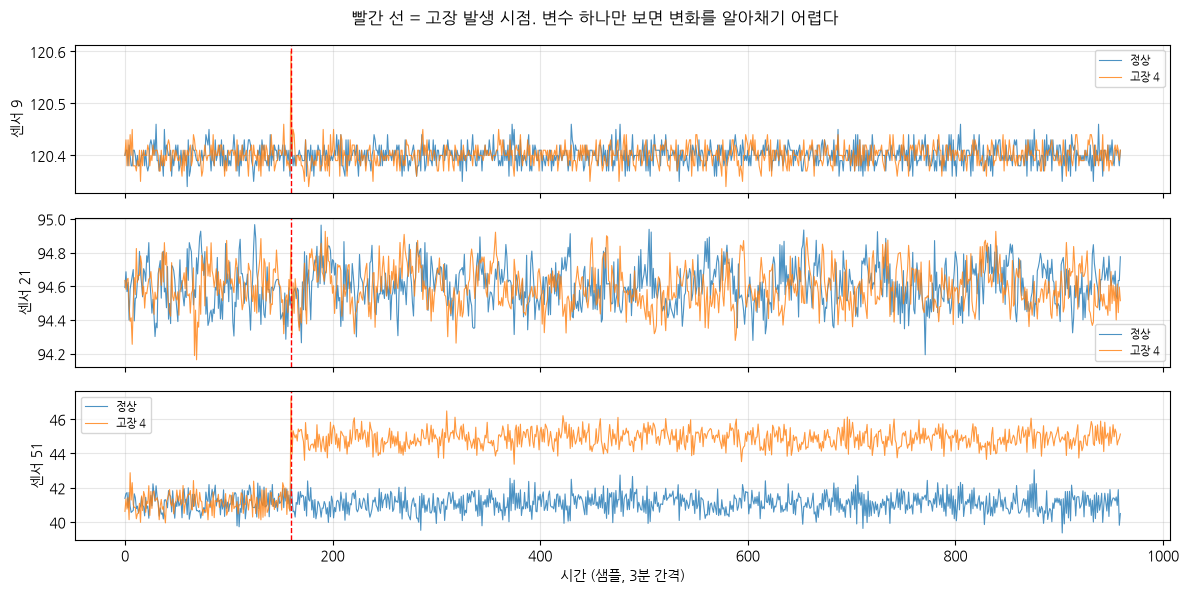

In [3]:
# 정상 운전과 고장 운전의 센서 신호 비교
fig, ax = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
for a, v in zip(ax, [8, 20, 50]):
    a.plot(tests["d00_te"][:, v], lw=0.8, label="정상", alpha=0.8)
    a.plot(tests["d04_te"][:, v], lw=0.8, label="고장 4", alpha=0.8)
    a.axvline(FAULT_START, color="red", ls="--", lw=1)
    a.set_ylabel(f"센서 {v+1}"); a.legend(fontsize=8); a.grid(alpha=0.3)
ax[-1].set_xlabel("시간 (샘플, 3분 간격)")
plt.suptitle("빨간 선 = 고장 발생 시점. 변수 하나만 보면 변화를 알아채기 어렵다", y=0.98); plt.tight_layout(); plt.show()

## 2. ⭐ PCA 기반 다변량 이상탐지 — T² 와 SPE(Q)
정상 데이터로 PCA 모델을 만들면 공정은 **"주성분이 만드는 정상 공간"** 안에서 움직입니다.
| 통계량 | 감시 대상 | 의미 |
|---|---|---|
| **Hotelling T²** | 정상 공간 **안**에서의 이동 | 운전점이 평소보다 멀리 갔다 (크기 이상) |
| **SPE (Q 통계)** | 정상 공간 **밖**의 잔차 | 변수 간 **관계 자체가 깨졌다** (구조 이상) |

> 제약 PAT 에서 NIR·Raman 스펙트럼 감시에 쓰는 바로 그 기법입니다.

In [4]:
scaler = StandardScaler().fit(train)
Ztr = scaler.transform(train)
pca = PCA(n_components=0.90).fit(Ztr)          # 분산 90% 설명
print(f"주성분 {pca.n_components_}개로 전체 변동의 90% 설명 (원래 변수 52개)")

def stats_of(X):
    z = scaler.transform(X)
    t = pca.transform(z)
    T2 = (t ** 2 / pca.explained_variance_).sum(1)
    SPE = ((z - pca.inverse_transform(t)) ** 2).sum(1)
    return T2, SPE

T2_tr, SPE_tr = stats_of(train)
LIM_T2, LIM_SPE = np.percentile(T2_tr, 99.9), np.percentile(SPE_tr, 99.9)
print(f"관리한계(정상 데이터 99.9 분위): T² = {LIM_T2:.1f},  SPE = {LIM_SPE:.1f}")

주성분 31개로 전체 변동의 90% 설명 (원래 변수 52개)
관리한계(정상 데이터 99.9 분위): T² = 54.8,  SPE = 14.1


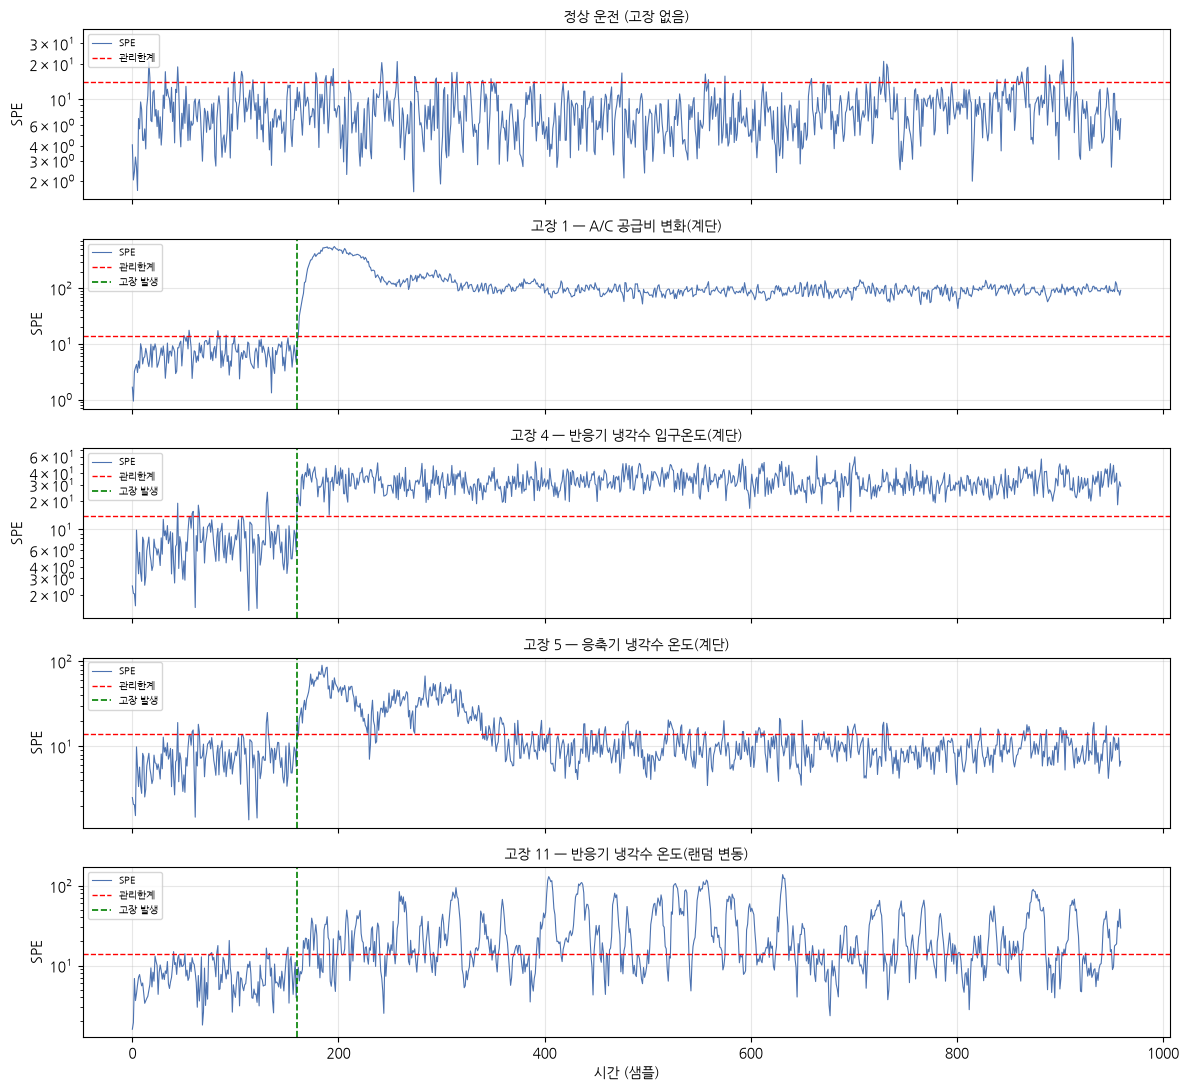

In [5]:
fig, ax = plt.subplots(len(FAULTS), 1, figsize=(12, 11), sharex=True)
for a, (k, name) in zip(ax, FAULTS.items()):
    T2, SPE = stats_of(tests[k])
    a.semilogy(SPE, lw=0.8, color="#4C72B0", label="SPE")
    a.axhline(LIM_SPE, color="red", ls="--", lw=1, label="관리한계")
    if k != "d00_te": a.axvline(FAULT_START, color="green", ls="--", lw=1.2, label="고장 발생")
    a.set_ylabel("SPE"); a.set_title(name, fontsize=10); a.legend(fontsize=7, loc="upper left"); a.grid(alpha=0.3)
ax[-1].set_xlabel("시간 (샘플)")
plt.tight_layout(); plt.show()

## 3. 탐지 성능 지표 — 탐지율·오경보율·**탐지 지연**
| 지표 | 의미 | GMP 해석 |
|---|---|---|
| **탐지율 (FDR)** | 고장 구간에서 경보가 울린 비율 | 높을수록 좋음 |
| **오경보율 (FAR)** | 정상 구간에서 경보가 울린 비율 | 낮을수록 좋음 (경보 피로) |
| **탐지 지연** | 고장 발생 ~ 첫 경보까지 시간 | **짧을수록 손실이 적다** |

> 연속 N점 규칙(예: 3점 연속 초과 시 경보)을 쓰면 **오경보는 줄고 지연은 늘어납니다.**

In [6]:
def evaluate(score, limit, fault_start=FAULT_START, consecutive=1):
    over = score > limit
    if consecutive > 1:
        over = pd.Series(over).rolling(consecutive).sum().eq(consecutive).fillna(False).values
    far = over[:fault_start].mean() if fault_start > 0 else np.nan
    fdr = over[fault_start:].mean()
    idx = np.where(over[fault_start:])[0]
    delay = (idx[0] * 3 if len(idx) else np.nan)      # 샘플 간격 3분
    return far, fdr, delay

rows = []
for k, name in FAULTS.items():
    T2, SPE = stats_of(tests[k])
    iso_sc = None
    for stat, sc_, lim in [("T²", T2, LIM_T2), ("SPE", SPE, LIM_SPE)]:
        for cons in [1, 3]:
            fs = 0 if k == "d00_te" else FAULT_START
            far, fdr, delay = evaluate(sc_, lim, fault_start=FAULT_START, consecutive=cons)
            rows.append({"시나리오": name[:18], "통계량": stat, "연속규칙": f"{cons}점",
                         "오경보율": far, "탐지율": fdr if k != "d00_te" else np.nan,
                         "탐지지연(분)": delay if k != "d00_te" else np.nan})
ev = pd.DataFrame(rows)
display(ev.pivot_table(index=["시나리오"], columns=["통계량", "연속규칙"], values="탐지율").round(2))
display(ev.pivot_table(index=["시나리오"], columns=["통계량", "연속규칙"], values="탐지지연(분)").round(0))

통계량                  SPE          T²      
연속규칙                  1점    3점    1점    3점
시나리오                                      
고장 1 — A/C 공급비 변화(  1.00  1.00  0.99  0.99
고장 11 — 반응기 냉각수 온도  0.64  0.46  0.58  0.35
고장 4 — 반응기 냉각수 입구온  1.00  1.00  0.60  0.28
고장 5 — 응축기 냉각수 온도(  0.33  0.23  0.29  0.24

통계량                  SPE          T²      
연속규칙                  1점    3점    1점    3점
시나리오                                      
고장 1 — A/C 공급비 변화(   3.0   9.0  12.0  24.0
고장 11 — 반응기 냉각수 온도  18.0  24.0  15.0  21.0
고장 4 — 반응기 냉각수 입구온   0.0   6.0   0.0  99.0
고장 5 — 응축기 냉각수 온도(   0.0  12.0   0.0   6.0

> **읽는 법**: SPE 가 T² 보다 대체로 민감합니다 — 고장은 보통 **변수 간 관계를 깨뜨리기** 때문입니다.
> 고장 5처럼 제어 루프가 보상해 버리는 고장은 탐지율이 낮습니다(정상으로 되돌아감) — 이런 고장은 **제어 신호(밸브 개도)** 를 함께 감시해야 합니다.

## 4. 다른 이상탐지 알고리즘과 비교
| 방법 | 원리 | 장점 | 단점 |
|---|---|---|---|
| **PCA SPE/T²** | 선형 정상공간 모델 | 빠름, **기여도 분석으로 원인 설명** | 비선형 관계에 약함 |
| **Isolation Forest** | 무작위 분할로 고립되기 쉬운 점 | 비선형·고차원 가능 | 설명 어려움, 시간 구조 무시 |
| **오토인코더** | 신경망 압축-복원 오차 | 복잡한 비선형 | 데이터·튜닝 필요 |
| **One-Class SVM** | 정상 영역 경계 학습 | 이론적 근거 | 느림, 스케일 민감 |

In [7]:
from sklearn.neural_network import MLPRegressor
from sklearn.svm import OneClassSVM

iso = IsolationForest(n_estimators=300, random_state=0).fit(Ztr)
ocsvm = OneClassSVM(nu=0.01, gamma="scale").fit(Ztr)
ae = MLPRegressor(hidden_layer_sizes=(32, 8, 32), max_iter=800, random_state=0, early_stopping=True).fit(Ztr, Ztr)

def ae_score(Z): return ((Z - ae.predict(Z)) ** 2).sum(1)
detectors = {
    "PCA SPE": (lambda Z: ((Z - pca.inverse_transform(pca.transform(Z))) ** 2).sum(1)),
    "Isolation Forest": (lambda Z: -iso.score_samples(Z)),
    "One-Class SVM": (lambda Z: -ocsvm.decision_function(Z)),
    "오토인코더": ae_score,
}
limits = {k: np.percentile(f(Ztr), 99.9) for k, f in detectors.items()}

rows = []
for name_d, f in detectors.items():
    row = {"방법": name_d, "오경보율(정상시험)": (f(scaler.transform(tests["d00_te"])) > limits[name_d]).mean()}
    for k, nm in FAULTS.items():
        if k == "d00_te": continue
        s = f(scaler.transform(tests[k]))
        row[nm.split("—")[0].strip()] = (s[FAULT_START:] > limits[name_d]).mean()
    rows.append(row)
pd.DataFrame(rows).round(3)

,방법,오경보율(정상시험),고장 1,고장 4,고장 5,고장 11
0,PCA SPE,0.057,0.999,1.000,0.331,0.636
1,Isolation Forest,0.053,0.934,0.068,0.311,0.176
2,One-Class SVM,0.430,1.000,0.999,0.668,0.902
3,오토인코더,0.052,0.996,0.961,0.291,0.705


## 5. ⭐ 기여도 분석 — "어느 센서 때문인가" (일탈 조사 지원)
경보만으로는 조치할 수 없습니다. **어떤 변수가 이상에 기여했는지** 보여줘야 조사 시간이 줄어듭니다.

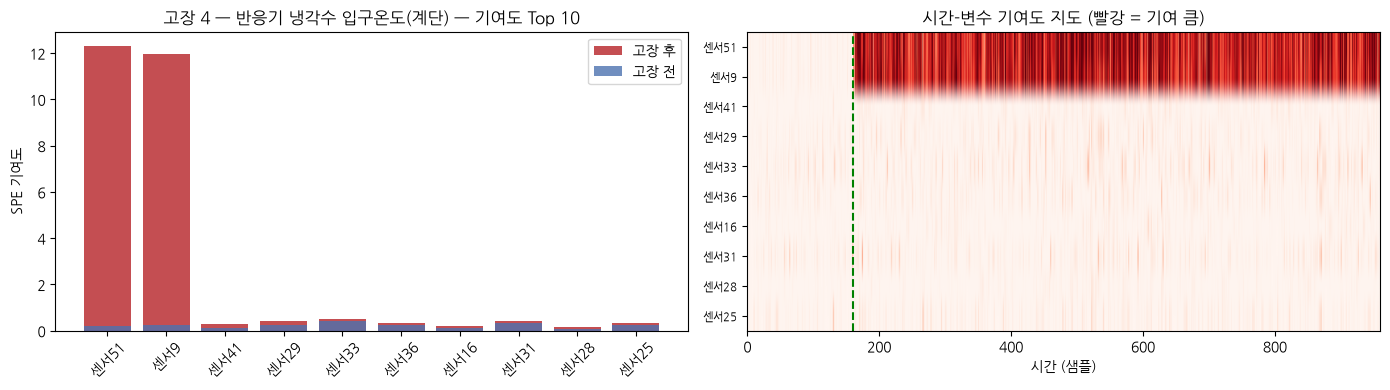

→ 상위 기여 센서 = 조사 착수 지점. 일탈 조사(Deviation Investigation) 보고서에 그대로 첨부할 수 있습니다.


In [8]:
k = "d04_te"
Z = scaler.transform(tests[k])
resid = Z - pca.inverse_transform(pca.transform(Z))
contrib = (resid ** 2)
after = contrib[FAULT_START:].mean(0)
before = contrib[:FAULT_START].mean(0)
order = np.argsort(after - before)[::-1][:10]

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(range(10), after[order], color="#C44E52", label="고장 후")
ax[0].bar(range(10), before[order], color="#4C72B0", alpha=0.8, label="고장 전")
ax[0].set_xticks(range(10)); ax[0].set_xticklabels([f"센서{i+1}" for i in order], rotation=45)
ax[0].set_ylabel("SPE 기여도"); ax[0].legend(); ax[0].set_title(f"{FAULTS[k]} — 기여도 Top 10")
ax[1].imshow(contrib[:, order].T, aspect="auto", cmap="Reds", vmax=np.percentile(contrib, 99.5))
ax[1].axvline(FAULT_START, color="green", ls="--")
ax[1].set_yticks(range(10)); ax[1].set_yticklabels([f"센서{i+1}" for i in order], fontsize=8)
ax[1].set_xlabel("시간 (샘플)"); ax[1].set_title("시간-변수 기여도 지도 (빨강 = 기여 큼)")
plt.tight_layout(); plt.show()
print("→ 상위 기여 센서 = 조사 착수 지점. 일탈 조사(Deviation Investigation) 보고서에 그대로 첨부할 수 있습니다.")

## 6. 일탈(Deviation) 기록 자동 분류 — QMS 자동화
제조 현장의 일탈 기록은 **자유 서술 텍스트**입니다. 수백~수천 건이 쌓이면 유형 분류·추세 분석이 어렵습니다.
**텍스트 → 숫자(TF-IDF) → 군집/분류** 로 자동화할 수 있습니다.

> 아래 텍스트는 **교육용으로 작성한 예시 문장**입니다 (실제 일탈 기록 아님).
> 실제 적용 시에는 사내 DMS(Deviation Management System) 데이터를 사용하고, **데이터 반출 금지 규정**을 확인하세요.

In [9]:
templates = {
    "설비 고장": ["타정기 상부 펀치 마모로 정제 외관 불량 발생", "충전기 노즐 막힘으로 충전량 편차 증가",
                "동결건조기 진공 펌프 압력 상승으로 공정 중단", "포장기 라벨 부착 센서 오작동으로 라인 정지",
                "교반기 모터 과열로 배양 공정 일시 중단", "컨베이어 벨트 이탈로 포장 공정 정지",
                "정제수 시스템 순환 펌프 고장으로 공급 중단", "캡슐 충전기 분말 공급 장치 간헐적 정지",
                "코팅기 분사 노즐 압력 저하로 코팅 중단", "멸균기 도어 잠금 장치 결함으로 운전 불가",
                "과립기 임펠러 베어링 소음 발생으로 설비 정지", "압축공기 공급 설비 압력 강하로 공정 지연",
                "칭량 저울 교정 상태 불량으로 사용 중지", "자동 검사기 카메라 초점 이상으로 검사 중단",
                "오토클레이브 온도 센서 응답 지연으로 운전 중단"],
    "환경 관리": ["무균 작업실 차압이 설정 범위 미달로 경보 발생", "충전실 부유입자 수치가 등급 기준 초과",
                "창고 보관 구역 온도가 25도를 초과", "탈의실 환기 설비 필터 차압 상승",
                "제조실 상대습도가 관리 범위 상한 초과", "무균 구역 환경 모니터링에서 미생물 검출",
                "냉장 보관고 온도 기록계 단시간 범위 이탈", "공조 설비 HEPA 필터 무결성 시험 지연",
                "클린룸 낙하균 측정 결과 관리 기준 초과", "제조 구역 조도가 기준 미달로 확인됨",
                "물류 창고 습도 상승으로 자재 보관 조건 이탈", "작업실 양압 유지 실패로 교차오염 우려 발생",
                "표면 미생물 시험에서 기준 초과 균수 검출", "폐수 처리 설비 가동 중단으로 배출 지연",
                "무균실 가운 착용 절차 미준수 사례 확인"],
    "문서/기록": ["배치기록서 서명 누락이 검토 단계에서 확인됨", "시험 원자료의 날짜 기재 오류 발견",
                "전자기록 감사추적에서 수정 사유 미기재 확인", "표준작업지침서 개정본 미배포 상태로 작업 수행",
                "검체 라벨의 배치번호 오기재 발견", "교육 이수 기록 미비 상태로 작업자 투입",
                "장비 사용 로그북 기재 누락 확인", "시험성적서 검토자 서명이 지연됨",
                "제조지시서 버전과 실제 작업 버전 불일치", "데이터 백업 기록이 보존 기간 요건 미충족",
                "전산 시스템 권한 부여 기록 미비 확인", "변경관리 문서 승인 전 작업 착수 사례",
                "교정 성적서 보관 누락이 자체 점검에서 확인", "출하 판정 기록의 첨부 자료 누락",
                "작업 중 기록이 실시간으로 작성되지 않음"],
    "원료/자재": ["원료 입고 검체의 수분 함량이 기준 초과", "포장 자재 치수가 규격 범위를 벗어남",
                "공급업체 변경 원료의 입도 분포 차이 확인", "부형제 로트의 벌크밀도 편차 발생",
                "원료 보관 기간 초과로 재시험 필요", "자재 외관 검사에서 이물 혼입 발견",
                "주성분 원료의 유연물질 함량 상승", "포장재 인쇄 내용 오류 발견",
                "원료 용기 밀봉 상태 불량으로 격리 조치", "자재 입고 수량이 발주서와 불일치",
                "원료 시험 결과 확인 전 불출된 사례", "포장 자재 로트 추적성 정보 누락",
                "부형제 공급사 변경에 따른 재검증 미완료", "원료 운송 중 온도 기록 이탈 확인",
                "자재 보관 구역 선입선출 원칙 미준수"],
    "공정 일탈": ["혼합 공정 시간이 지침서 범위를 초과", "타정 압력이 설정값 대비 과도하게 상승",
                "건조 공정 온도가 허용 범위를 일시 이탈", "코팅액 분사 속도가 설정 범위 밖으로 변동",
                "멸균 공정 F0 값이 목표에 미달", "충전 공정 중량 편차가 관리 한계 초과",
                "과립 수분 함량이 공정 관리 기준 초과", "용액 pH 조정 단계에서 목표값 이탈",
                "배양 공정 용존산소 농도가 설정 범위 이탈", "여과 공정 압력이 상한을 초과",
                "정제 경도가 공정 중 시험 기준을 벗어남", "혼합 순서가 지시서와 다르게 수행됨",
                "충전 속도 변경이 승인 없이 적용됨", "건조 종료 판정 기준 미충족 상태로 다음 단계 진행",
                "캡슐 충전 중량이 관리 범위를 반복 이탈"],
}
rows = []
for cat, texts in templates.items():
    for t in texts:
        rows.append({"유형": cat, "내용": t})
dev = pd.DataFrame(rows)
print("일탈 기록:", len(dev), "건 /", dev.유형.nunique(), "개 유형")
dev.sample(5, random_state=0)

일탈 기록: 75 건 / 5 개 유형


,유형,내용
52,원료/자재,포장재 인쇄 내용 오류 발견
57,원료/자재,부형제 공급사 변경에 따른 재검증 미완료
22,환경 관리,공조 설비 HEPA 필터 무결성 시험 지연
74,공정 일탈,캡슐 충전 중량이 관리 범위를 반복 이탈
28,환경 관리,폐수 처리 설비 가동 중단으로 배출 지연


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# 한국어는 띄어쓰기 기준 + 문자 n-gram 을 함께 쓰면 조사·어미 변화에 강해집니다
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)
V = vec.fit_transform(dev["내용"])
print("TF-IDF 행렬:", V.shape)

km = KMeans(n_clusters=5, n_init=50, random_state=0).fit(V)
dev["군집"] = km.labels_
print("정답 유형과 군집의 일치도 (ARI):", round(adjusted_rand_score(dev["유형"], dev["군집"]), 3))
print("\n군집 × 실제 유형 교차표:")
display(pd.crosstab(dev["군집"], dev["유형"]))

TF-IDF 행렬: (75, 631)


정답 유형과 군집의 일치도 (ARI): 0.234

군집 × 실제 유형 교차표:


유형,공정 일탈,문서/기록,설비 고장,원료/자재,환경 관리
군집,,,,,
0,2,9,0,3,1
1,1,0,13,1,3
2,1,4,0,2,4
3,8,0,1,1,4
4,3,2,1,8,3


In [11]:
# 지도학습 분류 — 과거 분류 이력이 있으면 새 기록을 자동 분류할 수 있다
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report

clf = make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True),
                    LogisticRegression(max_iter=3000, C=10))
pred = cross_val_predict(clf, dev["내용"], dev["유형"], cv=StratifiedKFold(4, shuffle=True, random_state=0))
print(classification_report(dev["유형"], pred, digits=3))

clf.fit(dev["내용"], dev["유형"])
new_reports = ["타정기 하부 펀치에서 이상 마찰음이 발생하여 설비를 정지함",
               "제조실 차압이 기준치 아래로 내려가 경보가 울림",
               "배치기록서에 작업자 서명 일자가 누락되어 있음"]
for t in new_reports:
    proba = clf.predict_proba([t])[0]
    i = proba.argmax()
    print(f"\n[{t}]\n  → 예측 유형: {clf.classes_[i]} (확률 {proba[i]:.0%})")

              precision    recall  f1-score   support

       공정 일탈      0.667     0.667     0.667        15
       문서/기록      0.778     0.933     0.848        15
       설비 고장      0.867     0.867     0.867        15
       원료/자재      0.647     0.733     0.688        15
       환경 관리      0.800     0.533     0.640        15

    accuracy                          0.747        75
   macro avg      0.752     0.747     0.742        75
weighted avg      0.752     0.747     0.742        75


[타정기 하부 펀치에서 이상 마찰음이 발생하여 설비를 정지함]
  → 예측 유형: 설비 고장 (확률 57%)

[제조실 차압이 기준치 아래로 내려가 경보가 울림]
  → 예측 유형: 환경 관리 (확률 63%)

[배치기록서에 작업자 서명 일자가 누락되어 있음]
  → 예측 유형: 문서/기록 (확률 77%)


> **데이터 양의 한계**: 이 예시는 75건뿐입니다. 실제 DMS 에는 수천 건이 쌓여 있어 정확도가 훨씬 높아집니다.
> 한국어 성능을 더 올리려면 ① 형태소 분석(konlpy·kiwipiepy)으로 어간 추출 ② 사전학습 한국어 임베딩(KoBERT·KR-SBERT) 활용
> ③ 유형 체계를 **상호배타적으로** 정비하는 것이 효과적입니다 (유형이 겹치면 사람도 모델도 헷갈립니다).
>
> **QMS 자동화의 실제 가치**
> - 일탈 기록 **유형·추세 자동 집계** → APR(연간 제품 품질 평가) 작성 시간 단축
> - 유사 과거 일탈·CAPA 자동 검색 → **반복 일탈** 식별
> - ⚠️ 자동 분류 결과는 **검토자가 승인**해야 하며, 분류 모델의 오류율을 문서화해야 합니다 (예제 08)

## 🧪 LLM 코딩 과제
```
TEP 데이터(정상 학습 train, 고장 시험 tests['d01_te'])와 scaler, pca 객체가 있어.
SPE 통계량에 EWMA(λ=0.3)를 적용해서 평활한 뒤 탐지율·오경보율·탐지지연을 다시 계산하고,
평활 전후를 한 그래프에 비교해줘. 한글 주석을 달아줘.
```

In [12]:
# ✏️ LLM 코딩 과제 코드 붙여넣기

## ✅ 정리
| 개념 | 핵심 |
|---|---|
| 비지도 이상탐지 | **정상 데이터만으로** 학습 — 불량 데이터가 희귀한 제조 현장에 적합 |
| SPE vs T² | SPE(관계 깨짐)가 대체로 더 민감. 둘을 **함께** 감시 |
| 평가 | 탐지율·오경보율 + **탐지 지연**. 연속 N점 규칙으로 균형 조정 |
| 알고리즘 선택 | 설명이 필요하면 PCA, 비선형이면 오토인코더 — **설명가능성이 GMP 의 제약** |
| 기여도 분석 | 경보 → 원인 변수 제시까지 해야 일탈 조사에 쓸 수 있다 |
| 일탈 텍스트 | TF-IDF + 군집/분류로 QMS 자동화, 단 **사람 검토 필수** |

➡️ **다음 예제 07**: 이미지 데이터 — **딥러닝 비전 검사(정제·바이알 외관)**